In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
signal = np.array([1,1,1,2,2,2,2,1,1,1,1,2,2,2,2,0,0,0,0,2,2,2,2,1,1,1,1,2,2,2,2,1,1,1,1,0,0,0,0,1,1,1,1,0,0,0,0,1,1,1,1])

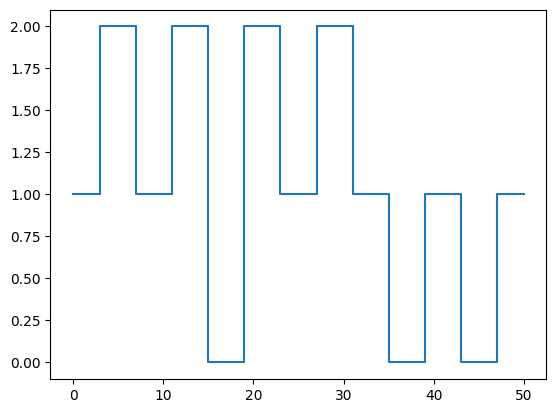

In [3]:
plt.plot(signal, drawstyle='steps-post')

In [4]:
sig = signal-1

(-2.1, 2.1)

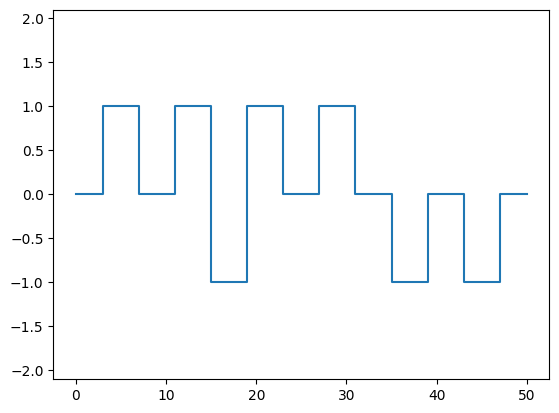

In [5]:
plt.plot(sig, drawstyle='steps-post')
plt.ylim([-2.1, 2.1])

In [6]:
sig_d = np.append(0, np.diff(sig))

In [7]:
changes = np.where(sig_d != 0)[0] 

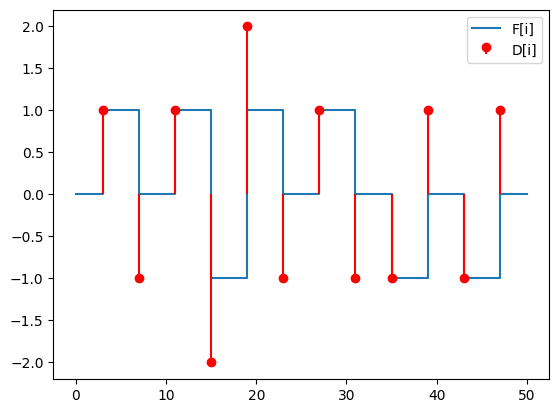

In [8]:
plt.plot(sig, drawstyle='steps-post', label='F[i]')
plt.stem(changes, sig_d[changes], linefmt='r', markerfmt='ro', basefmt=" ", label='D[i]')
plt.legend()

In [9]:
changes_d =  np.append(0, np.diff(sig_d[changes]))
interest = np.where((np.abs(changes_d) == 2))[0]

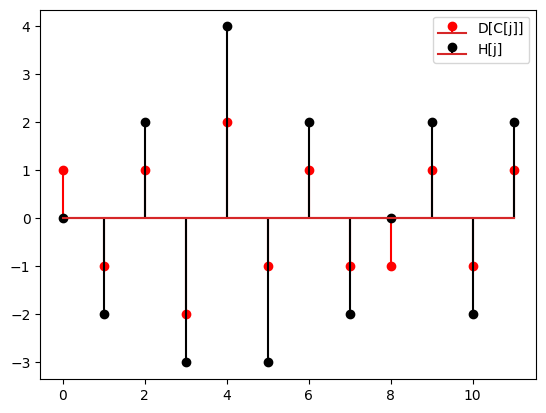

In [10]:
plt.stem(sig_d[changes], linefmt='r', markerfmt='ro', label='D[C[j]]')
plt.stem(changes_d, linefmt='k', markerfmt='ko', label='H[j]')
# plt.stem(interest, changes_d[interest], linefmt='g', markerfmt='g*', label='H[I[j]]')
plt.legend()


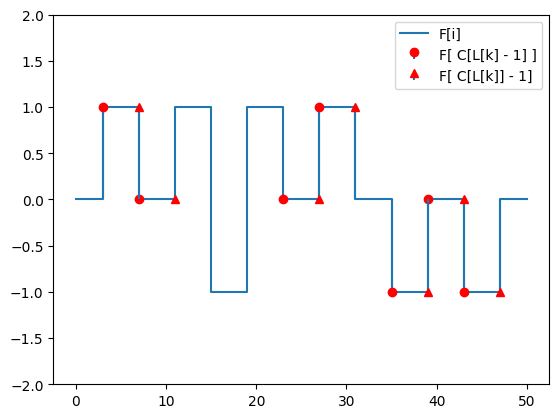

In [11]:
plt.plot(sig, drawstyle='steps-post', label='F[i]')
plt.stem(changes[interest-1], sig[changes[interest-1]], markerfmt='ro', basefmt=" ", label='F[ C[L[k] - 1] ]')
plt.stem(changes[interest], sig[changes[interest]-1], markerfmt='r^', basefmt=" ", label='F[ C[L[k]] - 1]')
plt.ylim([-2, 2])
plt.legend()

In [12]:
correction = np.zeros(sig.shape)
    
for start, end in zip(changes[interest -1], changes[interest]):
    if sig[start] == 0:
        correction[start:end] = sig[end]

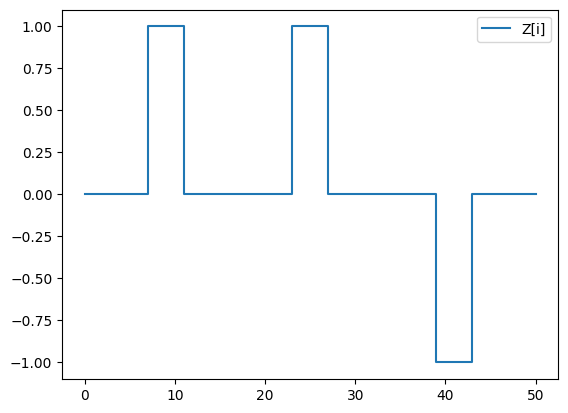

In [13]:
plt.plot(correction, drawstyle='steps-post', label='Z[i]')
plt.legend()

(-2.5, 2.5)

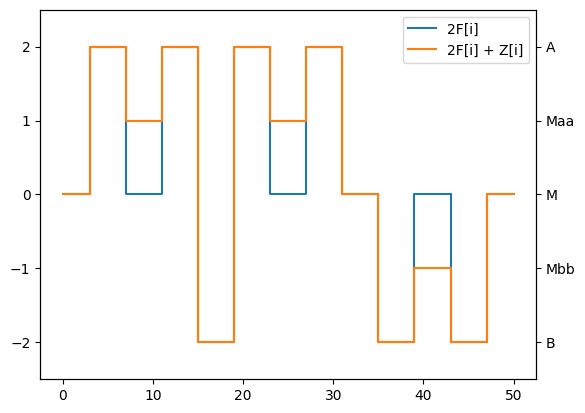

In [14]:
plt.plot(sig*2 , drawstyle='steps-post', label= '2F[i]')

plt.plot(sig*2 + correction, drawstyle='steps-post', label= '2F[i] + Z[i]')
plt.legend()
plt.yticks(ticks=np.arange(-2, 3))
plt.ylim([-2.5, 2.5])

plt.gca().twinx()
plt.yticks(ticks=np.arange(-2, 3), labels=['B', 'Mbb', 'M', 'Maa', 'A'])
plt.ylim([-2.5, 2.5])
